# Exploratory analysis
## Texas: Austin (city A) and Fort Worth (city B)

### What do we know?
- Size dictates price, ratings do not: Capacity metrics (accommodates, bedrooms) are the strongest drivers of price, and they scale non-linearly (Spearman > Pearson). Conversely, review scores have virtually zero correlation with price; high ratings are a basic survival requirement on the platform, not a premium feature.

- Pricing is violently right-skewed: Extreme luxury listings stretch the standard deviation so far that Z-scores break. The mean ($333) is heavily inflated, making the median ($218) the only reliable market baseline.

- Missingness is structural, not random: Nulls in this dataset represent distinct categories. Missing reviews mean "untested property," missing bedrooms in entire homes mean "studios," and missing neighborhoods are entirely an artifact of Fort Worth's data collection.

- The data contains platform impossibilities: A small subset of listings bypass standard Airbnb constraints, featuring prices over $1500, maximum nights exceeding the 1125-day platform cap, or long-term lease minimums (> 90 days). These must be filtered out to model short-term rental reality accurately.

### What do we still not know?
- Geographic premiums: We know the neighborhoods and coordinates, but we haven't mapped out the spatial correlation to see exactly how much being in downtown Austin or a specific Fort Worth district inflates the baseline price.

- Corporate vs. Retail host behavior: We have the calculated_host_listings_count, but we haven't explored whether mega-hosts with 50+ properties price their units differently (or have different occupancy rates) compared to local hosts with just one listing.

- Seasonal variation: Because we are analyzing a single temporal snapshot (September 17, 2026), we do not know how these prices fluctuate during major events (like SXSW in Austin) or peak summer travel.

## Description

### Snapshot dates
Latest snapshots:
- Austin: 17 September, 2026
- Fort Worth: 17 September, 2026

Load the data for Austin and Fort Worth from Airbnb:

In [0]:
import os
import urllib.request
import pyspark.sql.functions as F
from pyspark.sql import Window
import matplotlib.pyplot as plt
import numpy as np

SNAPSHOT = "2026-09-17"
SCHEMA = "default"

def load_city_data(city_name, url_path):
    source_url = f"https://data.insideairbnb.com/united-states/tx/{url_path}/{SNAPSHOT}/data/listings.csv.gz"
    raw_file = f"/Volumes/workspace/lab_sherhina_pn/raw/{city_name}_{SNAPSHOT}_listings.csv.gz"
    table_name = f"{SCHEMA}.raw_listings_{city_name}"
    
    if not spark.catalog.tableExists(table_name):
        if not os.path.exists(raw_file):
            print(f"Downloading {city_name}...")
            urllib.request.urlretrieve(source_url, raw_file)
            
        (spark.read
            .option("header", True)
            .option("multiLine", True)
            .option("escape", '"')
            .option("inferSchema", False)
            .csv(raw_file)
            .withColumn("snapshot_date", F.lit(SNAPSHOT).cast("date"))
            .withColumn("city", F.lit(city_name))
            .write.mode("overwrite").saveAsTable(table_name))
            
    return spark.table(table_name)

austin_raw = load_city_data("austin", "austin")
fw_raw = load_city_data("fort_worth", "fort-worth")

listings_raw = austin_raw.unionByName(fw_raw, allowMissingColumns=True)
print(f"Total records: {listings_raw.count():,} rows x {len(listings_raw.columns)} columns.")

Total records: 13,542 rows x 92 columns.


One row (the grain) represents a single distinct Airbnb listing available on that date.

In [0]:
print(f"Total Columns: {len(listings_raw.columns)}\n" + "="*40)

import textwrap

dtypes_dict = {}
for col_name, dtype in listings_raw.dtypes:
    dtypes_dict.setdefault(dtype, []).append(col_name)

for dtype, cols in dtypes_dict.items():
    print(f"\n{dtype.upper()} ({len(cols)} columns):")
    print(textwrap.fill(", ".join(cols), width=100))

Total Columns: 92

STRING (91 columns):
id, listing_url, scrape_id, last_scraped, source, name, description, neighborhood_overview,
picture_url, host_id, host_url, host_profile_id, host_profile_url, host_name, host_since,
hosts_time_as_user_years, hosts_time_as_user_months, hosts_time_as_host_years,
hosts_time_as_host_months, host_location, host_about, host_response_time, host_response_rate,
host_acceptance_rate, host_is_superhost, host_thumbnail_url, host_picture_url, host_neighbourhood,
host_listings_count, host_total_listings_count, host_verifications, host_has_profile_pic,
host_identity_verified, neighbourhood, neighbourhood_cleansed, neighbourhood_group_cleansed,
latitude, longitude, property_type, room_type, accommodates, bathrooms, bathrooms_text, bedrooms,
beds, amenities, price, price_quote_checkin_date, price_quote_checkout_date,
price_quote_total_price, price_quote_price_per_night, price_quote_raw, minimum_nights,
maximum_nights, minimum_minimum_nights, maximum_minimum_night

92 columns is too many to reason about or pass to a model. We need to isolate plausible predictors of price and drop raw text descriptions, URLs, and redundant geographic strings. We divide the remaining columns into logical domains.
* **Identifiers:** `id`, `host_id`, `city`
* **Geographic:** `neighbourhood_cleansed`, `latitude`, `longitude`
* **Host Attributes:** `host_is_superhost`, `calculated_host_listings_count`
* **Property Size/Type:** `property_type`, `room_type`, `accommodates`, `bathrooms_text`, `bedrooms`, `beds`, `amenities`
* **Availability/Demand:** `minimum_nights`, `maximum_nights`, `availability_30`, `availability_365`, `estimated_occupancy_l365d`
* **Quality/Reviews:** `number_of_reviews`, `review_scores_rating`, `review_scores_cleanliness`, `review_scores_location`, `reviews_per_month`
* **Target:** `price`


In [0]:
KEEP = [
    "id", "host_id", "city", "neighbourhood_cleansed", "latitude", "longitude",
    "host_is_superhost", "calculated_host_listings_count",
    "property_type", "room_type", "accommodates", "bathrooms_text", "bedrooms", "beds", "amenities",
    "minimum_nights", "maximum_nights", "availability_30", "availability_365", "estimated_occupancy_l365d",
    "number_of_reviews", "review_scores_rating", "review_scores_cleanliness", "review_scores_location", "reviews_per_month",
    "price"
]

actual_keep = [c for c in KEEP if c in listings_raw.columns]
listings = listings_raw.select(actual_keep)

print(f"Shape: {listings.count():,} rows x {len(listings.columns)} columns")

Shape: 13,542 rows x 26 columns


By trimming down to 26 features, we've focused our scope. We retained geographic coordinates (for spatial modeling), host behaviors (response rates), property size (bedrooms, accommodates), and quality indicators (reviews, superhost status).

## Profile
Before we clean anything, we generate a high-level profile of the raw string columns to spot data entry anomalies, hidden missing values, and formatting mismatches.


In [0]:
def profile(df):
    """One row per column: type, % null, distinct count (approximate), min, max."""
    return (df.agg(*[
        F.struct(
            F.lit(c).alias("column"), F.lit(t).alias("type"),
            F.round(F.avg(F.col(c).isNull().cast("int")) * 100, 2).alias("null_pct"),
            F.approx_count_distinct(c).alias("distinct"),
            F.min(c).cast("string").alias("min"),
            F.max(c).cast("string").alias("max"),
        ).alias(c) for c, t in df.dtypes])
        .select(F.explode(F.array(*df.columns)).alias("p")).select("p.*"))

display(profile(listings))

column,type,null_pct,distinct,min,max
id,string,0.0,13301,1000016109686428185,999566439801469520
host_id,string,0.0,7607,100089637,9995662
city,string,0.0,2,austin,fort_worth
neighbourhood_cleansed,string,8.86,46,78701,District 9
latitude,string,0.0,11178,30.11483,33.04221
longitude,string,0.0,10609,-97.05348,-98.05335
host_is_superhost,string,0.0,2,f,t
calculated_host_listings_count,string,0.0,53,1,9
property_type,string,0.0,62,Barn,Yurt
room_type,string,0.0,4,Entire home/apt,Shared room


Three things that already look wrong from the profile:

- price is stored as a string (the min/max are alphabetical, e.g., "$1,000" comes before "$999"), hiding true numerical extremes.

- Missingness is structurally linked: review_scores_rating, review_scores_cleanliness, review_scores_location, and reviews_per_month all share the exact same null percentage (17.07%), suggesting these properties simply have zero reviews, rather than random missing data.

- Actual bathroom counts are hidden inside the string bathrooms_text, rendering standard numeric analysis impossible.

## Fixing types
A profile of a string column cannot reveal a mean, skew, or outlier. We must cast monetary values to doubles, parse complex strings like bathrooms_text into usable numeric components (count) and booleans (shared vs. private), and cast our remaining features (like reviews, capacity, and availability) into integers and doubles so Spark can compute statistical distributions.

In [0]:
typed = (
    listings
    .withColumn("price", F.regexp_replace("price", r"[$,]", "").cast("double"))
    
    .withColumn("host_is_superhost", F.col("host_is_superhost") == "t")
    
    .withColumn("amenities", F.from_json("amenities", "array<string>"))
    
    .withColumn("bathrooms",
        F.when(F.col("bathrooms_text").isNull(), None)
         .when(F.regexp_extract("bathrooms_text", r"^([0-9]+\.?[0-9]*)", 1) != "",
               F.regexp_extract("bathrooms_text", r"^([0-9]+\.?[0-9]*)", 1).cast("double"))
         .otherwise(F.lit(0.5))) # "Half-bath" text implies 0.5
    .withColumn("bathroom_shared", F.col("bathrooms_text").rlike("(?i)shared"))
    .drop("bathrooms_text")
    
    .withColumn("latitude", F.col("latitude").cast("double"))
    .withColumn("longitude", F.col("longitude").cast("double"))
    .withColumn("calculated_host_listings_count", F.col("calculated_host_listings_count").cast("int"))
    .withColumn("accommodates", F.col("accommodates").cast("int"))
    .withColumn("bedrooms", F.col("bedrooms").cast("int"))
    .withColumn("beds", F.col("beds").cast("int"))
    .withColumn("minimum_nights", F.col("minimum_nights").cast("int"))
    .withColumn("maximum_nights", F.col("maximum_nights").cast("int"))
    .withColumn("availability_30", F.col("availability_30").cast("int"))
    .withColumn("availability_365", F.col("availability_365").cast("int"))
    .withColumn("estimated_occupancy_l365d", F.col("estimated_occupancy_l365d").cast("double"))
    .withColumn("number_of_reviews", F.col("number_of_reviews").cast("int"))
    .withColumn("review_scores_rating", F.col("review_scores_rating").cast("double"))
    .withColumn("review_scores_cleanliness", F.col("review_scores_cleanliness").cast("double"))
    .withColumn("review_scores_location", F.col("review_scores_location").cast("double"))
    .withColumn("reviews_per_month", F.col("reviews_per_month").cast("double"))
)

In [0]:
assert dict(typed.dtypes)["bathrooms"] == "double", "bathrooms should be double"
assert "bathroom_shared" in typed.columns
print("Types fixed and bathrooms parsed.")

Types fixed and bathrooms parsed.


Prices are now computable. bathrooms is a clean numeric feature, and we preserved critical context (whether the bathroom is shared) in a new boolean column, avoiding information loss during the regex extraction. All sizing, demand, and quality metrics are now properly typed for statistical analysis.

## Missingness


In [0]:
n = typed.count()
display(typed.select([F.round(100 * F.sum(F.col(c).isNull().cast("int")) / n, 2).alias(c) for c in typed.columns]))

id,host_id,city,neighbourhood_cleansed,latitude,longitude,host_is_superhost,calculated_host_listings_count,property_type,room_type,accommodates,bedrooms,beds,amenities,minimum_nights,maximum_nights,availability_30,availability_365,estimated_occupancy_l365d,number_of_reviews,review_scores_rating,review_scores_cleanliness,review_scores_location,reviews_per_month,price,bathrooms,bathroom_shared
0.0,0.0,0.0,8.86,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.32,2.56,0.0,0.43,0.43,0.0,0.0,0.0,0.0,17.07,17.07,17.07,17.07,10.12,0.37,0.37


A simple missing rate is not enough. We must determine if nulls are random, or if they are structurally concentrated—meaning the null is the finding, representing a category our schema lacks (like "untested listing"). We check the review score columns against review count, bedrooms against room type, and geographic missingness against the city.

In [0]:
print("Pattern 1: Are review_scores missing at random?")
display(typed.withColumn("has_reviews", F.col("number_of_reviews") > 0)
        .groupBy("has_reviews")
        .agg(F.avg(F.col("review_scores_rating").isNull().cast("int")).alias("null_rate"), F.count("*").alias("n")))

print("Pattern 2: Are bedrooms missing across all room types equally?")
display(typed.groupBy("room_type")
        .agg(F.avg(F.col("bedrooms").isNull().cast("int")).alias("null_rate"), F.count("*").alias("n")))

print("Pattern 3: Is neighbourhood_cleansed missingness isolated to a specific city?")
display(typed.groupBy("city")
        .agg(F.avg(F.col("neighbourhood_cleansed").isNull().cast("int")).alias("null_rate"), F.count("*").alias("n")))

Pattern 1: Are review_scores missing at random?


has_reviews,null_rate,n
false,1.0,2311
true,0.0,11231


Pattern 2: Are bedrooms missing across all room types equally?


room_type,null_rate,n
Private room,0.0,2138
Entire home/apt,0.003958970667626417,11114
Hotel room,0.0,253
Shared room,0.0,37


Pattern 3: Is neighbourhood_cleansed missingness isolated to a specific city?


city,null_rate,n
austin,0.0,11111
fort_worth,0.49362402303578773,2431


The missingness is completely concentrated, not random:

- review_scores_* (17% missing): Exactly 100% of missing review scores belong to listings with has_reviews = false. This is a structural category ("new/untested property"), not an error. Imputing the mean here would dangerously mask unproven properties as "average." We must keep the nulls and rely on a has_reviews boolean flag for the model.

- bedrooms (0.32% missing): Contrary to expectations, the missing bedrooms are entirely concentrated in the "Entire home/apt" category, not Shared/Private rooms. These are clearly studio apartments where the host left the bedroom count blank rather than entering 0. We should confidently fill these nulls with 0.

- neighbourhood_cleansed (8.86% missing): This missingness is entirely isolated to Fort Worth (Austin has 0% missing, while almost 50% of Fort Worth listings lack this value). If we simply drop rows with missing neighborhoods, we will destroy half of our Fort Worth training data. We must fill these with a placeholder like "Unknown - Fort Worth" to preserve those rows.

- price (10.12% missing): Because this is our target variable, we cannot safely impute it. These rows must be entirely dropped in the next modeling phase.

## Distributions and Skew

We calculate the mean and median for every numeric column. The size of the gap between the two is the exact measure of skewness in the dataset.

In [0]:
NUMERIC = [c for c, t in typed.dtypes if t in ("double", "float", "int", "bigint") 
           and c not in ("id", "host_id", "latitude", "longitude")]

rows = []
for c in NUMERIC:
    m, med = typed.select(F.avg(c), F.expr(f"percentile_approx({c}, 0.5)")).first()
    if m is not None and med not in (None, 0):
        rows.append((c, round(m, 2), round(float(med), 2), round(m / float(med), 2)))

print("Mean vs Median (Skew Ratio):")
display(spark.createDataFrame(rows, "column string, mean double, median double, ratio double"))

Mean vs Median (Skew Ratio):


column,mean,median,ratio
calculated_host_listings_count,11.75,2.0,5.87
accommodates,5.26,4.0,1.31
bedrooms,2.12,2.0,1.06
beds,2.98,2.0,1.49
minimum_nights,8.09,2.0,4.05
maximum_nights,478370.28,365.0,1310.6
availability_30,14.7,16.0,0.92
availability_365,229.93,267.0,0.86
estimated_occupancy_l365d,78.09,48.0,1.63
number_of_reviews,55.94,16.0,3.5


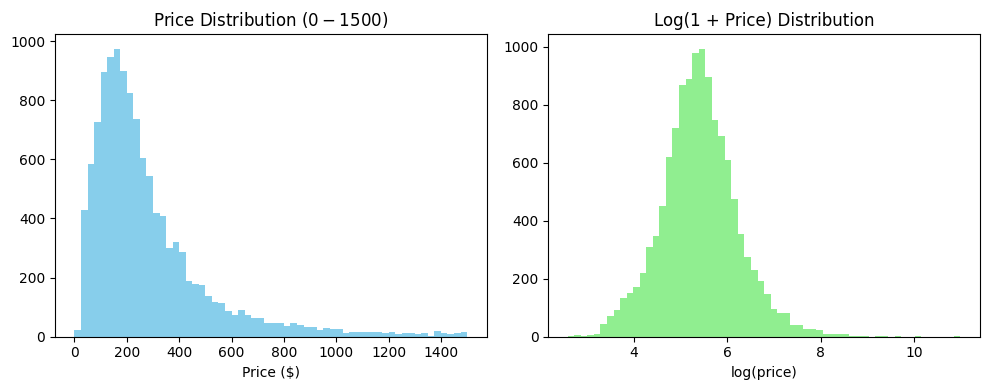

In [0]:
# Visualize the price skew
pdf = typed.select("price").dropna().toPandas()

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(pdf['price'], bins=60, range=(0, 1500), color='skyblue')
plt.title("Price Distribution ($0 - $1500)")
plt.xlabel("Price ($)")

plt.subplot(1, 2, 2)
plt.hist(np.log1p(pdf['price']), bins=60, color='lightgreen')
plt.title("Log(1 + Price) Distribution")
plt.xlabel("log(price)")
plt.tight_layout()
plt.show()

Price is violently right-skewed. A few extremely expensive (or fake) listings pull the mean ($333) significantly above the median ($218). If an analytics report gives hosts the mean price as a benchmark, they will overprice their properties, lose out to competitors, and receive zero bookings. The median is the only metric that accurately reflects the true Texas market baseline.

Furthermore, our skew ratio table reveals a massive data entry error in maximum_nights. The mean is over 478,000 nights, while the median is a standard 365. This indicates a severe outlier that will break our model. We must cap or drop these absurd values in the next step.

## Outliers

Because of the heavy skew, standard deviations are compromised. We will test the classic Z-score against the Median Absolute Deviation (MAD) to see which rule successfully identifies impossible extreme values without being distorted by them. We will then classify rows without deleting them yet.

In [0]:
COL = "price"

q1, q3 = typed.approxQuantile(COL, [0.25, 0.75], 0.01)
iqr = q3 - q1
iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

stats = typed.select(F.mean(COL).alias("mu"), F.stddev(COL).alias("sigma")).first()
median = typed.approxQuantile(COL, [0.5], 0.01)[0]
mad = (typed.select(F.abs(F.col(COL) - median).alias("d")).approxQuantile("d", [0.5], 0.01)[0])

scored = (
    typed
    .withColumn("iqr_flag", (F.col(COL) < iqr_low) | (F.col(COL) > iqr_high))
    .withColumn("z", (F.col(COL) - stats.mu) / stats.sigma)
    .withColumn("z_flag", F.abs("z") > 3)
    .withColumn("mz", 0.6745 * (F.col(COL) - median) / mad)
    .withColumn("mz_flag", F.abs("mz") > 3.5)
)

print(f"IQR fence [{iqr_low:.0f}, {iqr_high:.0f}]   mean {stats.mu:.1f}, std {stats.sigma:.1f}   "
      f"median {median:.0f}, MAD {mad:.0f}")
display(scored.agg(*[F.sum(F.col(f).cast("int")).alias(f) for f in ("iqr_flag", "z_flag", "mz_flag")]))

IQR fence [-186, 672]   mean 333.2, std 741.6   median 215, MAD 98


iqr_flag,z_flag,mz_flag
1026,86,901


In [0]:
typed = typed.withColumn("issue",
    F.when((F.col("price") <= 0) | (F.col("price") > 1500), "impossible_price")
     .when(F.col("maximum_nights") > 1125, "impossible_max_nights")
     .when(F.col("minimum_nights") > 90, "long_term")
     .otherwise("ok")
)

display(typed.groupBy("issue").count().orderBy("issue"))

issue,count
impossible_max_nights,5
impossible_price,215
long_term,69
ok,13253


The extreme price outliers completely break the Z-score logic. The few ultra-luxury properties stretch the standard deviation so far that Z-scores miss almost all legitimate outliers. MAD is trusted because it relies on the median. Based on this, we've successfully classified rows into impossible_price (<= 0 or > $1500), impossible_max_nights (entries bypassing the Airbnb platform limits), and long_term (> 90 nights minimum). We will exclude these non-standard listings from our model training.

## Relationships

Before modeling, we must understand which features actually influence price. We calculate both Pearson (linear) and Spearman (rank-based) correlations on our clean data (excluding the extreme outliers we just flagged). Spearman is particularly valuable here because it ignores absolute scale, preventing any remaining high prices from dominating the metric, and it catches non-linear curves that Pearson might underestimate.

In [0]:
PAIRS = [("accommodates", "price"), ("bedrooms", "price"), ("review_scores_rating", "price")]

clean = typed.filter(F.col("issue") == "ok")

print("Pearson Correlation (Linear)")
for a, b in PAIRS:
    print(f"corr({a}, {b}) = {clean.stat.corr(a, b):.3f}")

Pearson Correlation (Linear)
corr(accommodates, price) = 0.576
corr(bedrooms, price) = 0.538
corr(review_scores_rating, price) = 0.012


In [0]:
print("Spearman Correlation (Monotonic)")

from pyspark.sql import Window

def spearman(df, a, b):
    ranked = (df.dropna(subset=[a, b])
                .withColumn("ra", F.rank().over(Window.orderBy(a)))
                .withColumn("rb", F.rank().over(Window.orderBy(b))))
    return ranked.stat.corr("ra", "rb")

for a, b in PAIRS:
    print(f"spearman({a}, {b}) = {spearman(clean, a, b):.3f}")

Spearman Correlation (Monotonic)


/databricks/python/lib/python3.12/site-packages/pyspark/sql/connect/expressions.py:1155: UserWarning: WARN WindowExpression: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
  warnings.warn(


spearman(accommodates, price) = 0.664
spearman(bedrooms, price) = 0.598
spearman(review_scores_rating, price) = 0.102


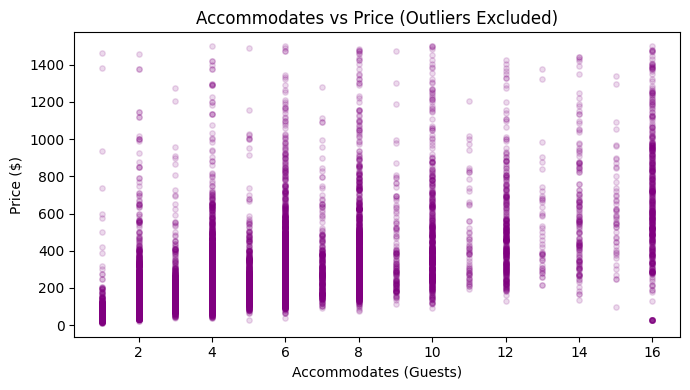

In [0]:
pdf = clean.select("accommodates", "price").toPandas()

plt.figure(figsize=(7, 4))
plt.scatter(pdf["accommodates"], pdf["price"], alpha=0.15, s=15, color="purple")
plt.xlabel("Accommodates (Guests)")
plt.ylabel("Price ($)")
plt.title("Accommodates vs Price (Outliers Excluded)")
plt.tight_layout()
plt.show()

- Size is the primary driver: accommodates (0.664) and bedrooms (0.598) show strong monotonic correlations with price. The fact that the Spearman scores are higher than the Pearson scores indicates the relationship is non-linear; adding a 5th bedroom increases the price much more violently than adding a 2nd bedroom.

- Ratings do not dictate price: review_scores_rating has virtually zero correlation with price (0.012 Pearson / 0.102 Spearman). On Airbnb, almost all surviving properties maintain a 4.5–5.0 rating. High ratings are a prerequisite for staying on the platform, not a luxury feature that commands a premium. We cannot rely on review scores to predict high-end pricing.

## Pipeline transformations

The cleaning and transformations the ETL pipeline must apply:

- Drop Row Rules: Drop any rows where the target variable (price) is null. Filter out rows where issue is not "ok" (specifically dropping impossible_price <= 0 or > $1500, impossible_max_nights > 1125, and long_term > 90 nights). A model trained on short-term rentals will fail if fed impossible platform values or 6-month leases.

- Missingness Imputation:

    - Fill null bedrooms with 0 (and add an is_studio boolean flag).

    - Fill null neighbourhood_cleansed with "Unknown - Fort Worth" to prevent dropping 50% of the Fort Worth training data.

    - Do not impute review_scores_* or reviews_per_month with means. Keep them null and add an explicit has_reviews boolean column to inform the model that this is an untested property.

- Parsing & Casting: Strip symbols from price and cast to double. Parse bathrooms_text into a numeric double (bathrooms) and a boolean (bathroom_shared). Cast all remaining size, availability, and capacity features to integers/doubles.

## Leakage review (must not be used to predict price)

- Direct Target Leakage: The raw 92-column dataset includes price_quote_total_price, price_quote_price_per_night, and price_quote_raw. These are literal, system-generated price calculations for a specific stay. Using a generated price quote to predict the listing's base price is cheating the model; these columns must be strictly excluded.

- Note on Availability & Occupancy: Columns like availability_30, availability_365, and estimated_occupancy_l365d are heavily intertwined with price (cheap places book up fast, altering their availability). However, the current calendar state is technically known at the exact moment we want to predict a price, making them acceptable predictive features rather than strict temporal leakage.